# LAB 1 - Bài 2 (Trang 15-17): Phân tích và tiền xử lý dữ liệu Titanic

# Câu 1: Nhập dữ liệu và thống kê thông tin cơ bản
### 1.1 Khai báo thư viện và đọc dữ liệu

In [ ]:

HO_TEN = "Nguyễn Đoàn Ngọc Hiệp"
MSSV = "6451071023"

def info():
    print(f"Họ và tên: {HO_TEN} - MSSV: {MSSV}")
    print("-" * 30)

# Linear algebra & data processing
import re
import numpy as np
import pandas as pd

# Data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style

# Đọc dữ liệu từ file titanic.csv
with open('titanic.csv') as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

### 1.2 Xem xét dữ liệu ban đầu

In [ ]:
info()
df.head(12)

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
5,1,1,"Anderson, Mr. Harry",male,48.0000,0,0,19952,26.5500,E12,S,3,NaN,"New York, NY"
6,1,1,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,0,13502,77.9583,D7,S,10,NaN,"Hudson, NY"
7,1,0,"Andrews, Mr. Thomas Jr",male,39.0000,0,0,112050,0.0000,A36,S,NaN,NaN,"Belfast, NI"
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,2,0,11769,51.4792,C101,S,D,NaN,"Bayside, Queens, NY"
9,1,0,"Artagaveytia, Mr. Ramon",male,71.0000,0,0,PC 17609,49.5042,NaN,C,NaN,22.0,"Montevideo, Uruguay"


In [ ]:
info()
df.info()

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB


### 1.3 Thống kê mô tả các thuộc tính

In [ ]:
info()
df.describe(include='all')

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
count,1309.000000,1309.000000,1309,1309,1046.000000,1309.000000,1309.000000,1309,1308.000000,295,1307,486,121.000000,745
unique,NaN,NaN,1307,2,NaN,NaN,NaN,929,NaN,186,3,27,NaN,369
top,NaN,NaN,"Kelly, Mr. James",male,NaN,NaN,NaN,CA. 2343,NaN,C23 C25 C27,S,13,NaN,"New York, NY"
freq,NaN,NaN,2,843,NaN,NaN,NaN,11,NaN,6,914,39,NaN,64
mean,2.294882,0.381971,NaN,NaN,29.881135,0.498854,0.385027,NaN,33.295479,NaN,NaN,NaN,160.809917,NaN
std,0.837836,0.486055,NaN,NaN,14.413500,1.041658,0.865560,NaN,51.758668,NaN,NaN,NaN,97.696922,NaN
min,1.000000,0.000000,NaN,NaN,0.166700,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN
25%,2.000000,0.000000,NaN,NaN,21.000000,0.000000,0.000000,NaN,7.895800,NaN,NaN,NaN,72.000000,NaN
50%,3.000000,0.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,NaN,155.000000,NaN
75%,3.000000,1.000000,NaN,NaN,39.000000,1.000000,0.000000,NaN,31.275000,NaN,NaN,NaN,256.000000,NaN


# Câu 2: Thống kê dữ liệu khuyết thiếu

In [ ]:
info()
# Lấy ra 5 thuộc tính có số lượng giá trị rỗng nhiều nhất
total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])

print("5 thuộc tính có số lượng giá trị rỗng nhiều nhất:")
display(missing_data.head(5))

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
5 thuộc tính có số lượng giá trị rỗng nhiều nhất:


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1


# Câu 3: Khảo sát Độ tuổi, Giới tính và Khả năng sống sót

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


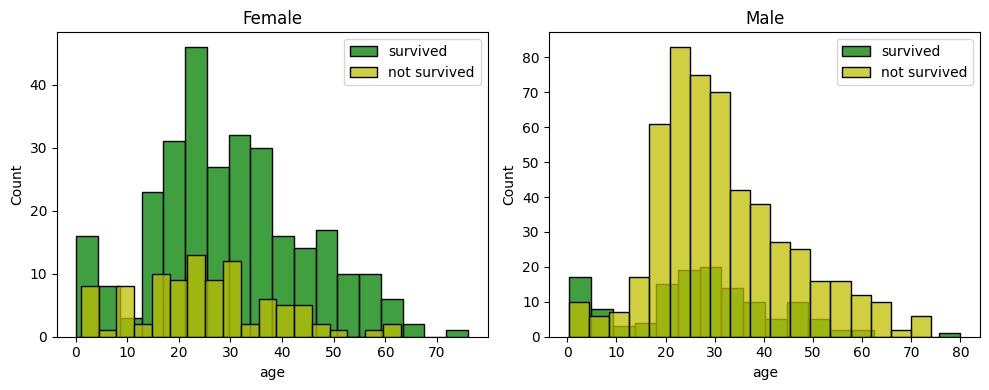

In [ ]:
info()
survived = 'survived'
not_survived = 'not survived'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

# Nữ
ax = sns.histplot(women[women['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[0], kde=False, color='g')
ax = sns.histplot(women[women['survived'] == 0].age.dropna(), bins=18, label=not_survived, ax=axes[0], kde=False, color='y')
ax.legend()
ax.set_title('Female')

# Nam
ax = sns.histplot(men[men['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[1], kde=False, color='g')
ax = sns.histplot(men[men['survived'] == 0].age.dropna(), bins=18, label=not_survived, ax=axes[1], kde=False, color='y')
ax.legend()
ax.set_title('Male')

plt.tight_layout()
plt.show()

# Câu 4: Khảo sát Cổng lên tàu, Loại vé và Khả năng sống sót (phân biệt theo giới tính)
### 4.1 Embarked - Pclass - Survived theo Sex

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


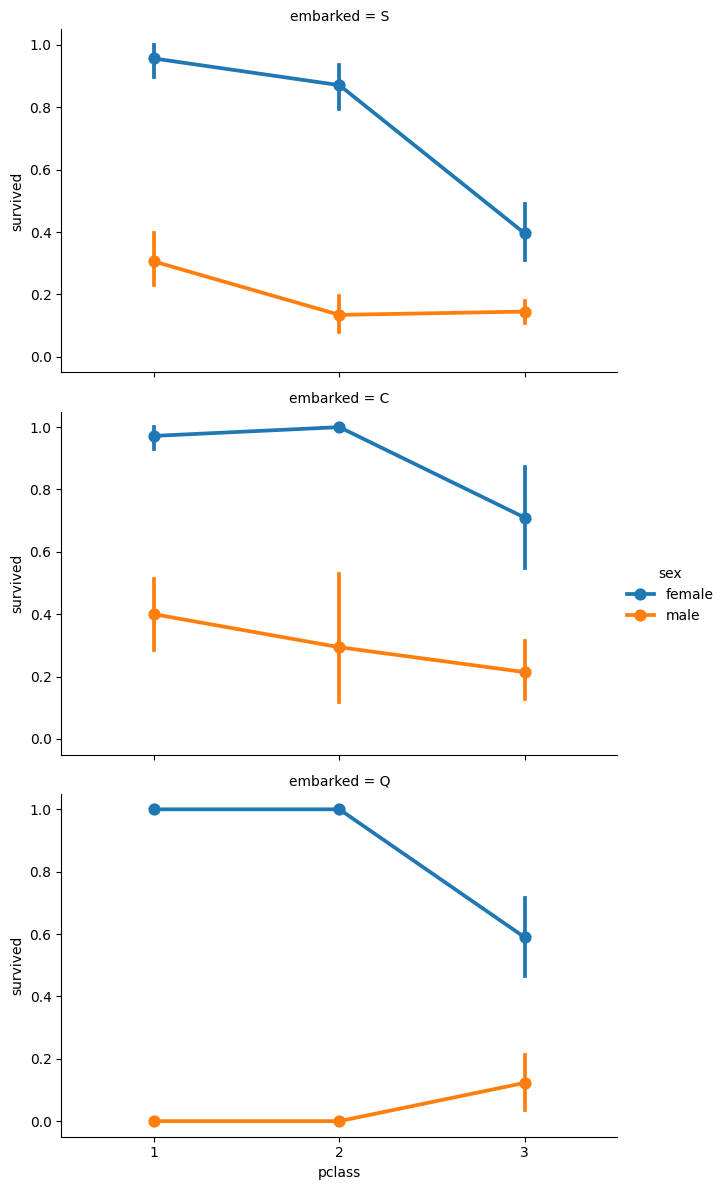

In [ ]:
info()
sns.catplot(data=df, x='pclass', y='survived', hue='sex', row='embarked',
            kind='point', order=[1, 2, 3], height=4, aspect=1.6)
plt.show()

### 4.2 Tỷ lệ sống sót theo Loại vé (pclass)

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


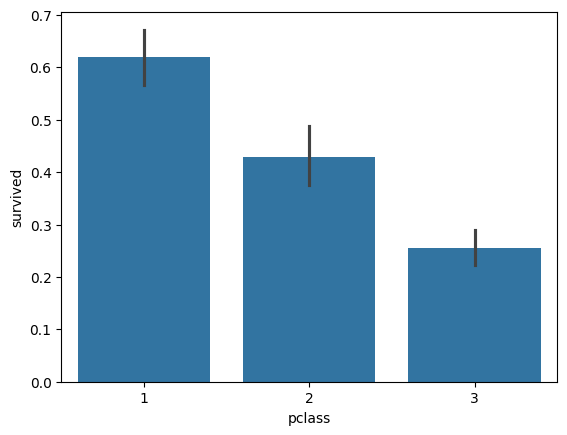

In [ ]:
info()
sns.barplot(x='pclass', y='survived', data=df)
plt.show()

### 4.3 Phân phối độ tuổi theo Loại vé (pclass) và Khả năng sống sót (survived)

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


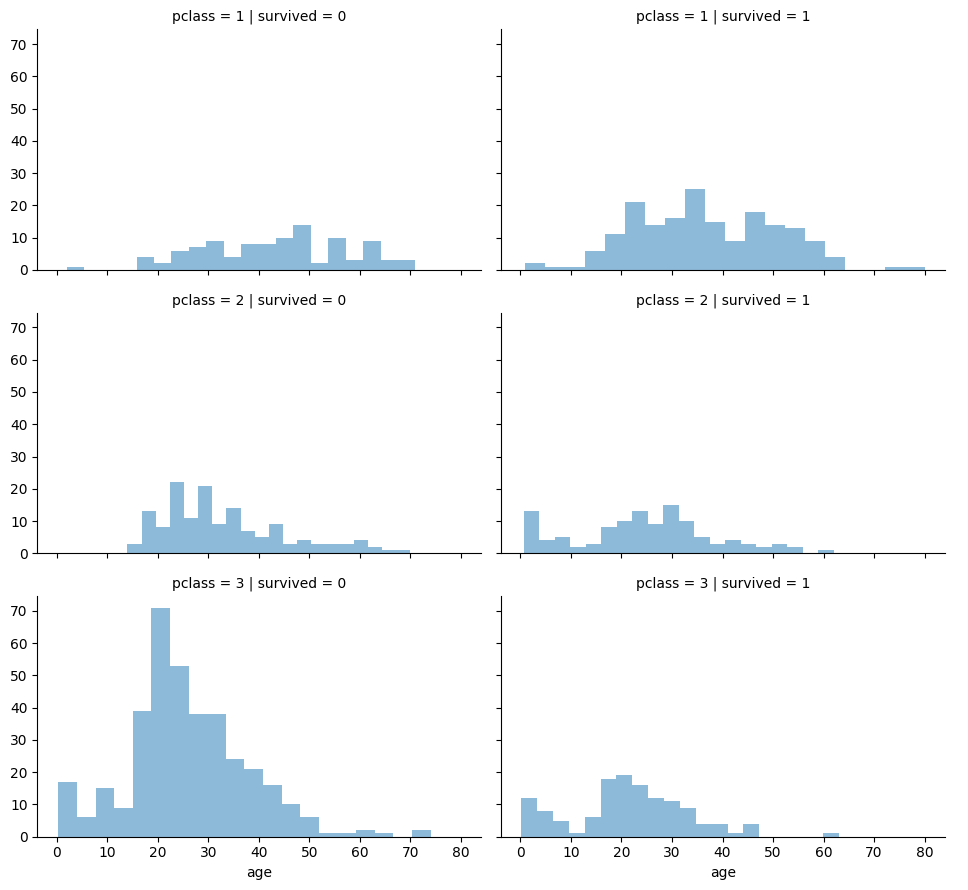

In [ ]:
info()
grid = sns.FacetGrid(df, col='survived', row='pclass', height=3, aspect=1.6)
grid.map(plt.hist, 'age', alpha=0.5, bins=20)
grid.add_legend()
plt.show()

**Nhận xét:** (viết nhận xét của bạn sau khi xem biểu đồ)

# Câu 5: Số người đi cùng và Khả năng sống sót
### 5.1 Thống kê số người đi một mình và đi cùng người thân

In [ ]:
info()
df['relatives'] = df['sibsp'] + df['parch']
df['not_alone'] = (df['relatives'] == 0).astype(int)   # 1 = đi một mình (giữ đúng quy ước của bài mẫu)

print(df['not_alone'].value_counts())
print("-" * 30)
print(df['relatives'].value_counts().sort_index())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
not_alone
1    790
0    519
Name: count, dtype: int64
------------------------------
relatives
0     790
1     235
2     159
3      43
4      22
5      25
6      16
7       8
10     11
Name: count, dtype: int64


### 5.2 Mối quan hệ giữa số người đi cùng (relatives) và survived

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


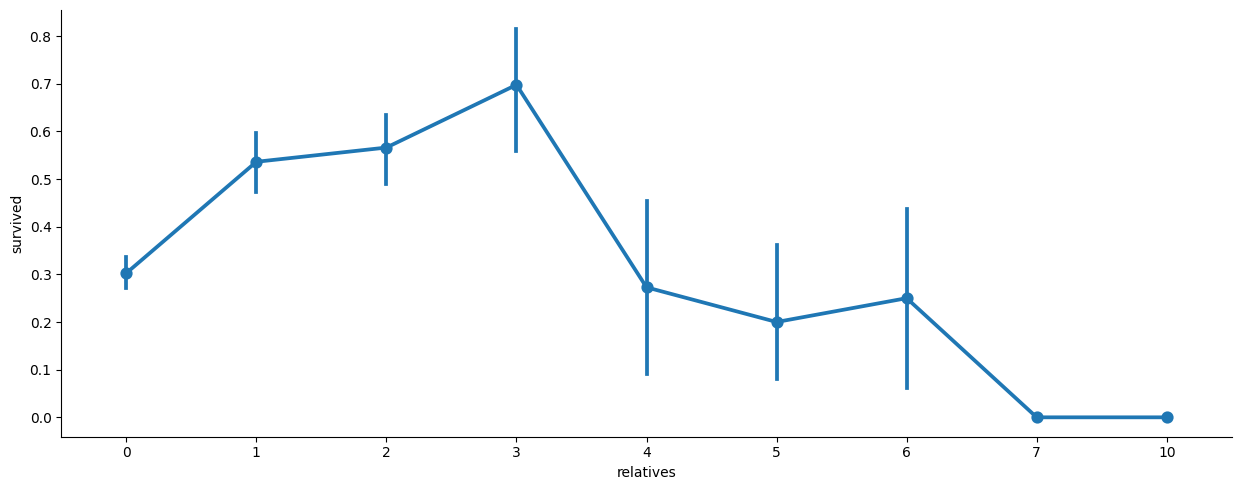

In [ ]:
info()
sns.catplot(x='relatives', y='survived', data=df, aspect=2.5, kind='point')
plt.show()

# Câu 6: Tiền xử lý dữ liệu
### 6.1 Xử lý thuộc tính cabin

In [ ]:
info()
# Ánh xạ ký tự boong (deck) sang số
deck = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}

df['cabin'] = df['cabin'].fillna("U0")
df['deck'] = df['cabin'].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group())
df['deck'] = df['deck'].map(deck)
df['deck'] = df['deck'].fillna(0)
df['deck'] = df['deck'].astype(int)

# Xóa cột cabin sau khi đã trích xuất xong
df = df.drop(['cabin'], axis=1)

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


### 6.2 Xem xét và xóa các thuộc tính không cần thiết


In [ ]:
print("Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023")
print("-" * 30)
# Kiểm tra mô tả thuộc tính ticket
print(df['ticket'].describe())
print("-" * 30)

# Thực hiện xóa các thuộc tính không cần thiết
df = df.drop(['ticket'], axis=1)
df = df.drop(['boat'], axis=1)
df = df.drop(['body'], axis=1)
df = df.drop(['home.dest'], axis=1)

print("Đã xóa các thuộc tính không cần thiết thành công!")

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
count         1309
unique         929
top       CA. 2343
freq            11
Name: ticket, dtype: object
------------------------------
Đã xóa các thuộc tính không cần thiết thành công!


### 6.3 Điền giá trị thiếu cho tuổi (age)

### 6.4 Điền giá trị thiếu cho cổng lên tàu (embarked)

In [ ]:
info()
print(df['embarked'].describe())
print("-" * 30)
for dataset in [df]:
    mean = df["age"].mean()
    std = df["age"].std()
    is_null = dataset["age"].isnull().sum()

    # Tạo giá trị ngẫu nhiên giữa mean - std và mean + std
    rand_age = np.random.randint(mean - std, mean + std, size=is_null)

    # Điền vào các vị trí NaN
    age_slice = dataset["age"].copy()
    age_slice[np.isnan(age_slice)] = rand_age
    dataset["age"] = age_slice
    dataset["age"] = df["age"].astype(int)

# Kiểm tra lại số lượng giá trị null của age (phải bằng 0)
print("Số lượng giá trị null còn lại của age:", df["age"].isnull().sum())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
count     1307
unique       3
top          S
freq       914
Name: embarked, dtype: object
------------------------------
Số lượng giá trị null còn lại của age: 0


### 6.5 Điền giá trị thiếu cho giá vé (fare)

In [ ]:
info()
print("Số null của fare trước khi điền:", df['fare'].isnull().sum())
df['fare'] = df['fare'].fillna(df['fare'].median())
print("Số null của fare sau khi điền:", df['fare'].isnull().sum())
print("-" * 30)
print(df.isnull().sum())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
Số null của fare trước khi điền: 1
Số null của fare sau khi điền: 0
------------------------------
pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
fare         0
embarked     2
relatives    0
not_alone    0
deck         0
dtype: int64
